# Bradley–Terry recovery versus items, using Choix

In [ ]:
# Import Choix, numerical tools, and plotting utilities.
from pathlib import Path
from time import perf_counter
import choix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.special import expit

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()),
    Path.cwd(),
)
table_dir = repo_root / "results/tables/bradley_terry"
figure_dir = repo_root / "docs/thesis/images/experiments/bradley_terry"
table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

print("Choix version:", getattr(choix, "__version__", "installed"))


Choix version: installed


In [2]:
# Set the items, total comparison budgets, and data per item.
SEED = 20260831
ITEM_COUNTS = (10, 20, 50, 100, 200)
FIXED_M = (1_000, 5_000, 20_000, 100_000)
M_PER_ITEM = (100, 500)
COMPARISON_SWEEP = (50, 100, 200, 500, 1_000, 2_000, 5_000,
                    10_000, 20_000, 50_000, 100_000)
RUNS = 5
MAX_ITER = 1_000
TOL = 1e-8
GRADIENT_THRESHOLD = 1e-4

settings = sorted(
    {(n, m) for n in ITEM_COUNTS for m in FIXED_M}
    | {(n, n * ratio) for n in ITEM_COUNTS for ratio in M_PER_ITEM}
    | {(10, m) for m in COMPARISON_SWEEP}
)
settings_table = pd.DataFrame(settings, columns=["items_n", "comparisons_m"])
settings_table["expected_appearances_per_item"] = (
    2 * settings_table["comparisons_m"] / settings_table["items_n"]
)
display(settings_table)


,items_n,comparisons_m,expected_appearances_per_item
0,10,50,10.0
1,10,100,20.0
2,10,200,40.0
3,10,500,100.0
4,10,1000,200.0
5,10,2000,400.0
6,10,5000,1000.0
7,10,10000,2000.0
8,10,20000,4000.0
9,10,50000,10000.0


## 2. Generate the observations

In [3]:
# Simulate (winner, loser) observations and build Choix's wins matrix.
def simulate_pairs(theta, m, rng):
    n = len(theta)
    first = rng.integers(n, size=m)
    second = rng.integers(n - 1, size=m)
    second += second >= first
    first_wins = rng.random(m) < expit(theta[first] - theta[second])
    winners = np.where(first_wins, first, second)
    losers = np.where(first_wins, second, first)
    return winners, losers


def wins_matrix(n, winners, losers):
    return np.bincount(
        winners * n + losers, minlength=n * n
    ).reshape(n, n).astype(float)


example_theta = np.array([-0.6, -0.2, 0.2, 0.6])
example_w, example_l = simulate_pairs(
    example_theta, 20, np.random.default_rng(SEED)
)
print("First five (winner, loser) observations:", list(zip(example_w[:5], example_l[:5])))
print("Choix input: wins[i, j] = number of times i beat j")
display(pd.DataFrame(wins_matrix(4, example_w, example_l)))


First five (winner, loser) observations: [(np.int64(3), np.int64(1)), (np.int64(2), np.int64(0)), (np.int64(2), np.int64(1)), (np.int64(2), np.int64(0)), (np.int64(1), np.int64(0))]
Choix input: wins[i, j] = number of times i beat j


,0,1,2,3
0,0.0,2.0,1.0,0.0
1,2.0,0.0,2.0,1.0
2,3.0,4.0,0.0,1.0
3,2.0,2.0,0.0,0.0


## 3. Fit BT parameters with Choix


In [4]:
# Measure average NLL and its scaled gradient at the Choix estimate.
def bt_diagnostics(wins, theta):
    n = len(theta)
    m = wins.sum()
    margin = theta[:, None] - theta[None, :]
    mean_nll = np.sum(wins * np.logaddexp(0, -margin)) / m
    expected_wins = (wins + wins.T) * expit(margin)
    gradient = (expected_wins.sum(axis=1) - wins.sum(axis=1)) / m
    return float(mean_nll), float(n * np.max(np.abs(gradient)))


def fit_with_choix(wins):
    n = len(wins)
    components = connected_components(
        csr_matrix(wins), directed=True, connection="strong"
    )[0]
    if components != 1:
        return None, "no_finite_mle", components, np.nan, np.nan

    try:
        estimate = choix.ilsr_pairwise_dense(
            wins, alpha=0.0, max_iter=MAX_ITER, tol=TOL
        )
    except RuntimeError:
        return None, "max_iter_reached", components, np.nan, np.nan

    estimate = np.asarray(estimate, dtype=float)
    estimate -= estimate.mean()
    if not np.all(np.isfinite(estimate)):
        return None, "nonfinite_estimate", components, np.nan, np.nan

    mean_nll, gradient_inf = bt_diagnostics(wins, estimate)
    status = "converged" if gradient_inf < GRADIENT_THRESHOLD else "gradient_large"
    return estimate, status, components, mean_nll, gradient_inf


## 4. Baseline parameter recovery ($n=10$, $m=1,000$)

,item,true_parameter,estimated_parameter,absolute_error
0,0,0.5149,0.6824,0.1675
1,1,0.5020,0.6150,0.1130
2,2,-1.4789,-1.5360,0.0570
3,3,-0.9230,-1.1874,0.2644
4,4,0.2057,0.0825,0.1232
5,5,0.6088,0.5062,0.1026
6,6,-0.1632,-0.1474,0.0159
7,7,-0.7334,-0.7595,0.0261
8,8,0.4573,0.5933,0.1360
9,9,1.0098,1.1507,0.1409


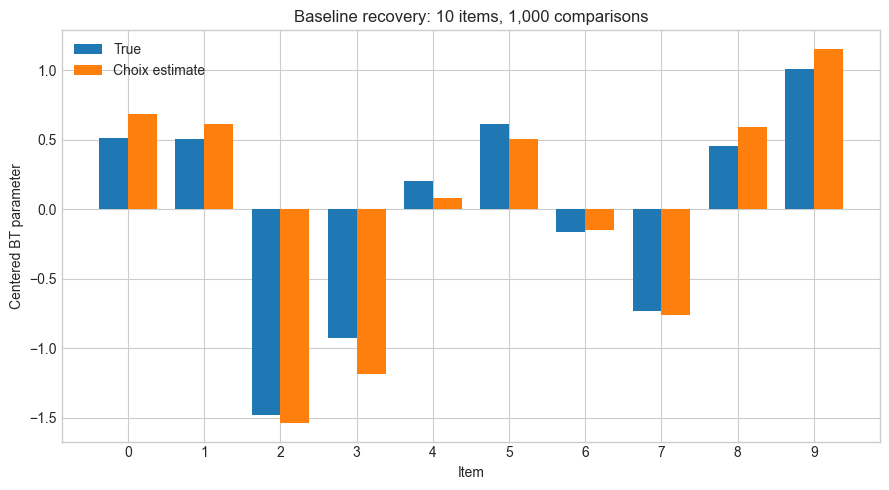

Baseline RMSE: 0.1337609061630661
Scaled gradient: 6.460265211671867e-11
Saved:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_baseline_parameter_recovery.pdf
and
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry/bt_choix_baseline_parameter_recovery.csv


In [5]:
# Plot and log one reproducible true-versus-estimated baseline.
baseline_n, baseline_m, baseline_run = 10, 1_000, 0
baseline_parameter_rng = np.random.default_rng([SEED, baseline_n, baseline_run, 0])
baseline_data_rng = np.random.default_rng([SEED, baseline_n, baseline_m, baseline_run, 1])
baseline_true = baseline_parameter_rng.normal(0, 1, baseline_n)
baseline_true -= baseline_true.mean()
baseline_w, baseline_l = simulate_pairs(baseline_true, baseline_m, baseline_data_rng)
baseline_wins = wins_matrix(baseline_n, baseline_w, baseline_l)
baseline_estimate, baseline_status, _, _, baseline_gradient = fit_with_choix(baseline_wins)

if baseline_status == "converged":
    baseline_table = pd.DataFrame({
        "item": np.arange(baseline_n),
        "true_parameter": baseline_true,
        "estimated_parameter": baseline_estimate,
        "absolute_error": np.abs(baseline_estimate - baseline_true),
    })
    baseline_path = table_dir / "bt_choix_baseline_parameter_recovery.csv"
    baseline_table.to_csv(baseline_path, index=False)
    display(baseline_table)

    positions = np.arange(baseline_n)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(positions - 0.19, baseline_true, width=0.38, label="True")
    ax.bar(positions + 0.19, baseline_estimate, width=0.38, label="Choix estimate")
    ax.set(xlabel="Item", ylabel="Centered BT parameter",
           title="Baseline recovery: 10 items, 1,000 comparisons")
    ax.set_xticks(positions)
    ax.legend()
    fig.tight_layout()
    baseline_figure = figure_dir / "bt_choix_baseline_parameter_recovery.pdf"
    fig.savefig(baseline_figure, bbox_inches="tight")
    plt.show()
    print("Baseline RMSE:", np.sqrt(np.mean((baseline_estimate - baseline_true) ** 2)))
    print("Scaled gradient:", baseline_gradient)
    print("Saved:", baseline_figure, "and", baseline_path, sep="\n")
else:
    print(f"Baseline status: {baseline_status}; no recovery figure or CSV was saved.")


## 5. Run the grid and save one row for every dataset

In [6]:
# Repeat the experiment and record timing, error, coverage, and fit status.
rows = []

for n, m in settings:
    for run in range(RUNS):
        parameter_rng = np.random.default_rng([SEED, n, run, 0])
        data_rng = np.random.default_rng([SEED, n, m, run, 1])
        true_theta = parameter_rng.normal(0, 1, n)
        true_theta -= true_theta.mean()

        start = perf_counter()
        winners, losers = simulate_pairs(true_theta, m, data_rng)
        wins = wins_matrix(n, winners, losers)
        generation_seconds = perf_counter() - start
        appearances = np.bincount(
            np.concatenate([winners, losers]), minlength=n
        )

        start = perf_counter()
        estimate, status, components, mean_nll, gradient_inf = fit_with_choix(wins)
        estimation_seconds = perf_counter() - start
        rmse = (
            np.sqrt(np.mean((estimate - true_theta) ** 2))
            if status == "converged" else np.nan
        )

        rows.append({
            "n": n, "m": m, "run": run + 1,
            "m_per_item": m / n,
            "expected_appearances_per_item": 2 * m / n,
            "minimum_appearances": int(appearances.min()),
            "unobserved_items": int(np.count_nonzero(appearances == 0)),
            "strong_components": components,
            "status": status, "scaled_gradient_inf": gradient_inf,
            "mean_nll": mean_nll, "rmse": rmse,
            "generation_seconds": generation_seconds,
            "estimation_seconds": estimation_seconds,
        })
    pd.DataFrame(rows).to_csv(table_dir / "bt_choix_item_scaling_runs.csv", index=False)
    print(f"Completed n={n:3d}, m={m:6,d}")

run_log = pd.DataFrame(rows)
run_path = table_dir / "bt_choix_item_scaling_runs.csv"
run_log.to_csv(run_path, index=False)
display(run_log.head(12))
print("Run log:", run_path)


Completed n= 10, m=    50
Completed n= 10, m=   100
Completed n= 10, m=   200
Completed n= 10, m=   500
Completed n= 10, m= 1,000
Completed n= 10, m= 2,000
Completed n= 10, m= 5,000
Completed n= 10, m=10,000
Completed n= 10, m=20,000
Completed n= 10, m=50,000
Completed n= 10, m=100,000
Completed n= 20, m= 1,000
Completed n= 20, m= 2,000
Completed n= 20, m= 5,000
Completed n= 20, m=10,000
Completed n= 20, m=20,000
Completed n= 20, m=100,000
Completed n= 50, m= 1,000
Completed n= 50, m= 5,000
Completed n= 50, m=20,000
Completed n= 50, m=25,000
Completed n= 50, m=100,000
Completed n=100, m= 1,000
Completed n=100, m= 5,000
Completed n=100, m=10,000
Completed n=100, m=20,000
Completed n=100, m=50,000
Completed n=100, m=100,000
Completed n=200, m= 1,000
Completed n=200, m= 5,000
Completed n=200, m=20,000
Completed n=200, m=100,000


,n,m,run,m_per_item,expected_appearances_per_item,minimum_appearances,unobserved_items,strong_components,status,scaled_gradient_inf,mean_nll,rmse,generation_seconds,estimation_seconds
0,10,50,1,5.0,10.0,7,0,1,converged,2.1605e-09,0.4808,0.7995,3.3421e-04,1.0126e-02
1,10,50,2,5.0,10.0,7,0,1,converged,3.6424e-09,0.4476,0.8911,5.9583e-05,1.6890e-03
2,10,50,3,5.0,10.0,6,0,2,no_finite_mle,NaN,NaN,NaN,4.9250e-05,1.2604e-04
3,10,50,4,5.0,10.0,7,0,6,no_finite_mle,NaN,NaN,NaN,3.4000e-04,2.6879e-04
4,10,50,5,5.0,10.0,6,0,1,converged,2.0124e-09,0.3847,1.3512,2.9916e-05,1.2424e-03
5,10,100,1,10.0,20.0,15,0,1,converged,1.3047e-09,0.5075,0.6404,1.3362e-04,1.1870e-03
6,10,100,2,10.0,20.0,15,0,1,converged,1.9288e-09,0.4323,0.6409,3.6125e-05,8.6392e-04
7,10,100,3,10.0,20.0,13,0,1,converged,1.6306e-09,0.4723,0.1811,2.7958e-05,1.1488e-03
8,10,100,4,10.0,20.0,12,0,1,converged,1.4959e-09,0.5339,0.4323,2.9625e-05,8.3017e-04
9,10,100,5,10.0,20.0,16,0,2,no_finite_mle,NaN,NaN,NaN,2.7041e-05,9.2667e-05


Run log: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry/bt_choix_item_scaling_runs.csv


In [7]:
# Summarize the valid runs and keep track of missing MLEs and fit failures.
summary = run_log.groupby(["n", "m"], as_index=False).agg(
    finite_mle_runs=("strong_components", lambda x: int((x == 1).sum())),
    converged_runs=("status", lambda x: int((x == "converged").sum())),
    mean_rmse=("rmse", "mean"),
    rmse_std=("rmse", "std"),
    mean_seconds=("estimation_seconds", "mean"),
)
summary["converged_fraction"] = summary["converged_runs"] / RUNS
summary["excluded_runs"] = RUNS - summary["converged_runs"]
summary_path = table_dir / "bt_choix_item_scaling_summary.csv"
summary.to_csv(summary_path, index=False)
display(summary)
print("Summary table:", summary_path)

# Explicitly count each exclusion reason (zero means none at that setting).
status_counts = (
    run_log.groupby(["n", "m", "status"]).size()
    .unstack(fill_value=0).reset_index()
)
for status in ("converged", "no_finite_mle", "max_iter_reached",
               "gradient_large", "nonfinite_estimate"):
    if status not in status_counts:
        status_counts[status] = 0
status_path = table_dir / "bt_choix_fit_status_counts.csv"
status_counts.to_csv(status_path, index=False)
print("Fit-status table:", status_path)


,n,m,finite_mle_runs,converged_runs,mean_rmse,rmse_std,mean_seconds,converged_fraction,excluded_runs
0,10,50,3,3,1.0139,0.2957,0.0027,0.6,2
1,10,100,4,4,0.4737,0.2184,0.0008,0.8,1
2,10,200,5,5,0.3220,0.0965,0.0025,1.0,0
3,10,500,5,5,0.2261,0.0273,0.0007,1.0,0
4,10,1000,5,5,0.1915,0.0514,0.0009,1.0,0
5,10,2000,5,5,0.1101,0.0378,0.0005,1.0,0
6,10,5000,5,5,0.0703,0.0256,0.0004,1.0,0
7,10,10000,5,5,0.0517,0.0177,0.0006,1.0,0
8,10,20000,5,5,0.0316,0.0094,0.0004,1.0,0
9,10,50000,5,5,0.0240,0.0064,0.0005,1.0,0


Summary table: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry/bt_choix_item_scaling_summary.csv
Fit-status table: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry/bt_choix_fit_status_counts.csv


## 6. Thesis figures: comparisons, items and fit status

In [8]:
# Use the same destination and naming convention for every thesis figure.
figure_paths = []

def save_thesis_figure(fig, filename):
    fig.tight_layout()
    path = figure_dir / filename
    fig.savefig(path, bbox_inches="tight")
    figure_paths.append(path)
    plt.show()
    print("Saved figure:", path)


### 6.1 Comparisons and recovery


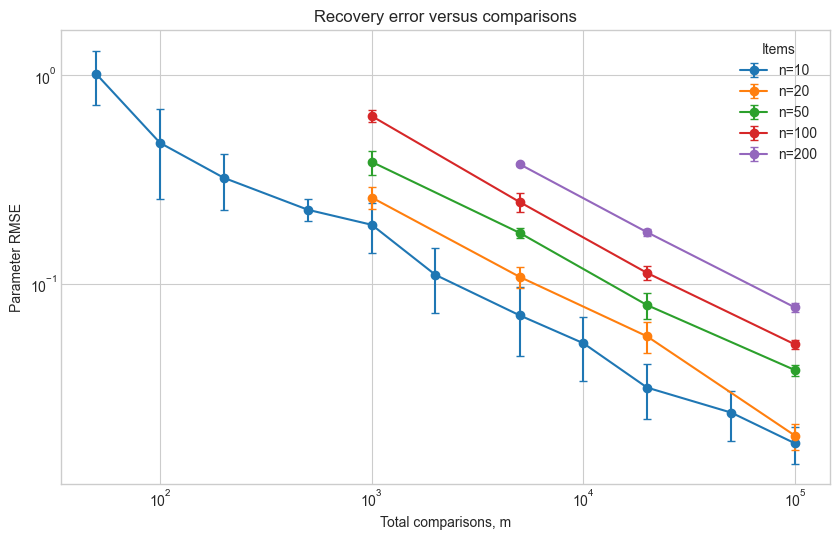

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_recovery_vs_comparisons.pdf


In [9]:
# One curve per n; n=10 includes the detailed comparison sweep.
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for n in ITEM_COUNTS:
    selected_m = COMPARISON_SWEEP if n == 10 else FIXED_M
    subset = summary[(summary["n"] == n) & summary["m"].isin(selected_m)]
    subset = subset.dropna(subset=["mean_rmse"]).sort_values("m")
    ax.errorbar(subset["m"], subset["mean_rmse"],
                yerr=subset["rmse_std"].fillna(0), marker="o",
                capsize=3, label=f"n={n}")
ax.set(xscale="log", yscale="log", xlabel="Total comparisons, m",
       ylabel="Parameter RMSE", title="Recovery error versus comparisons")
ax.legend(title="Items")
save_thesis_figure(fig, "bt_choix_recovery_vs_comparisons.pdf")


n=10 log-log slope (descriptive): -0.513


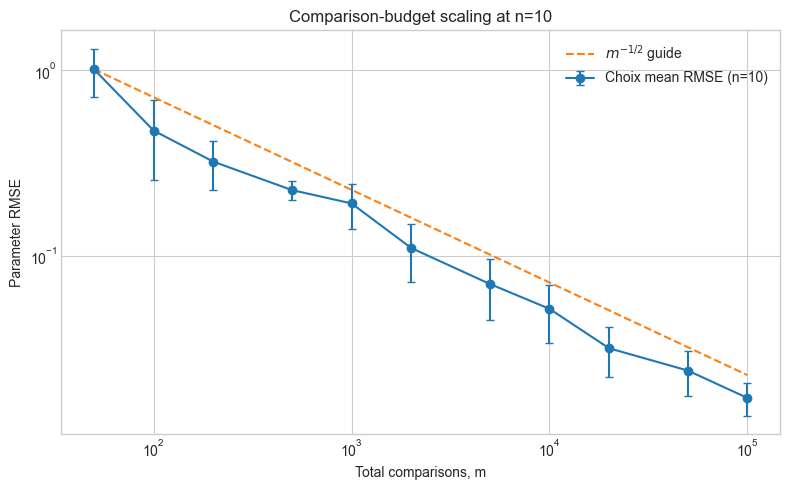

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_comparison_rate.pdf


In [10]:
# Compare the n=10 trend with an m^(-1/2) guide (not a fitted claim).
subset = summary[(summary["n"] == 10) & summary["m"].isin(COMPARISON_SWEEP)]
valid = subset.dropna(subset=["mean_rmse"]).sort_values("m")
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(valid["m"], valid["mean_rmse"],
            yerr=valid["rmse_std"].fillna(0), marker="o",
            capsize=3, label="Choix mean RMSE (n=10)")
if not valid.empty:
    first_m, first_rmse = valid.iloc[0][["m", "mean_rmse"]]
    guide = first_rmse * np.sqrt(first_m / valid["m"].to_numpy())
    ax.plot(valid["m"], guide, "--", label=r"$m^{-1/2}$ guide")
if len(valid) >= 3:
    slope = np.polyfit(np.log(valid["m"]), np.log(valid["mean_rmse"]), 1)[0]
    print(f"n=10 log-log slope (descriptive): {slope:.3f}")
ax.set(xscale="log", yscale="log", xlabel="Total comparisons, m",
       ylabel="Parameter RMSE", title="Comparison-budget scaling at n=10")
ax.legend()
save_thesis_figure(fig, "bt_choix_comparison_rate.pdf")


### 6.2 Number of items at fixed total $m$


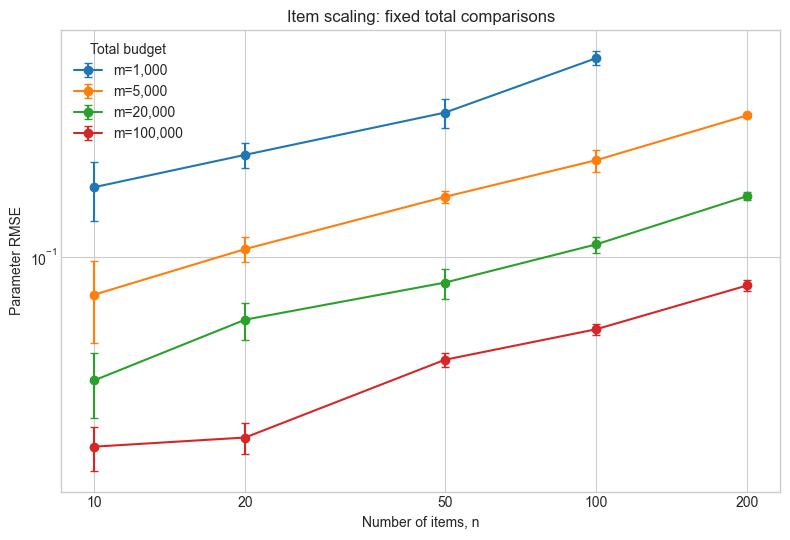

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_recovery_vs_items_fixed_m.pdf


In [11]:
# Only the same four total budgets are compared across all n.
fig, ax = plt.subplots(figsize=(8, 5.5))
for m in FIXED_M:
    subset = summary[summary["m"] == m].dropna(subset=["mean_rmse"])
    subset = subset.sort_values("n")
    ax.errorbar(subset["n"], subset["mean_rmse"],
                yerr=subset["rmse_std"].fillna(0), marker="o",
                capsize=3, label=f"m={m:,}")
ax.set(xscale="log", yscale="log", xlabel="Number of items, n",
       ylabel="Parameter RMSE", title="Item scaling: fixed total comparisons")
ax.set_xticks(ITEM_COUNTS, labels=ITEM_COUNTS)
ax.legend(title="Total budget")
save_thesis_figure(fig, "bt_choix_recovery_vs_items_fixed_m.pdf")


### 6.3 Number of items at fixed $m/n$


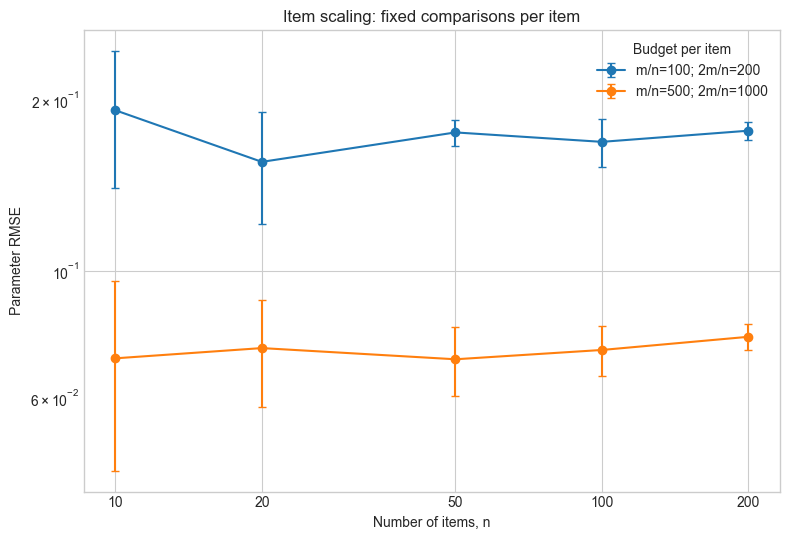

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_recovery_vs_items_fixed_ratio.pdf


In [12]:
# Match data per item: m = n * ratio.
fig, ax = plt.subplots(figsize=(8, 5.5))
for ratio in M_PER_ITEM:
    subset = summary[summary["m"] == summary["n"] * ratio]
    subset = subset.dropna(subset=["mean_rmse"]).sort_values("n")
    ax.errorbar(subset["n"], subset["mean_rmse"],
                yerr=subset["rmse_std"].fillna(0), marker="o",
                capsize=3, label=f"m/n={ratio}; 2m/n={2*ratio}")
ax.set(xscale="log", yscale="log", xlabel="Number of items, n",
       ylabel="Parameter RMSE", title="Item scaling: fixed comparisons per item")
ax.set_xticks(ITEM_COUNTS, labels=ITEM_COUNTS)
ax.legend(title="Budget per item")
save_thesis_figure(fig, "bt_choix_recovery_vs_items_fixed_ratio.pdf")


### 6.4 Fit coverage and runtime


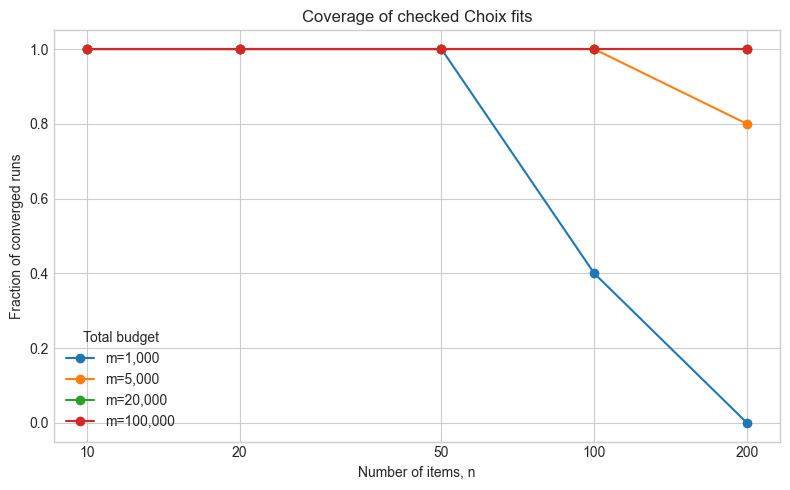

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/bt_choix_fit_coverage.pdf


In [13]:
# Show which item-scaling points are backed by checked fits.
fig, ax = plt.subplots(figsize=(8, 5))
for m in FIXED_M:
    subset = summary[summary["m"] == m].sort_values("n")
    ax.plot(subset["n"], subset["converged_fraction"],
            marker="o", label=f"m={m:,}")
ax.set(xscale="log", xlabel="Number of items, n",
       ylabel="Fraction of converged runs", ylim=(-0.05, 1.05),
       title="Coverage of checked Choix fits")
ax.set_xticks(ITEM_COUNTS, labels=ITEM_COUNTS)
ax.legend(title="Total budget")
save_thesis_figure(fig, "bt_choix_fit_coverage.pdf")
